# 📊 Proyek Portofolio Data Analis: SF Restaurant Inspection Scores
## Bagian 2: Exploratory Data Analysis (EDA) & Ekstraksi Wawasan Bisnis (*Actionable Insights*)

**Penulis:** Gilang Anugrah  
**Dataset:** San Francisco Restaurant Inspection Scores (LIVES Standard)  
**Kerangka Kerja:** Data Analytics Lifecycle — Tahap 4: ANALYZE

---
### 🎯 Pertanyaan Bisnis yang Dijawab dalam Notebook Ini:
1. **Profil Kepatuhan Sanitasi:** Bagaimana sebaran mutu sanitasi restoran secara umum di San Francisco?
2. **Karakteristik Pelanggaran:** Jenis pelanggaran apa yang paling lazim terjadi dan apa saja ancaman *High Risk* terbesar?
3. **Tren Temporal & Musiman:** Bagaimana perkembangan mutu kebersihan dari tahun ke tahun dan apakah ada fenomena musiman (*seasonality*)?
4. **Pemetaan Area Kritis:** Kode pos mana yang memiliki risiko pelanggaran tinggi dan membutuhkan atensi pengawasan lebih?
5. **Evaluasi Dampak Regulasi:** Apakah intervensi inspeksi ulang (*re-inspection*) terbukti efektif memulihkan restoran berskor rendah?

In [3]:
# 1. Mengimpor pustaka utama untuk analisis data, visualisasi statistik, dan manajemen file
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Mengatur konfigurasi visualisasi grafik (style, palet warna, dan resolusi gambar)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

# Membuat folder output untuk menyimpan gambar grafik laporan jika belum ada
figures_dir = os.path.join('..', 'reports', 'figures')
if not os.path.exists(figures_dir):
    figures_dir = os.path.join('reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)

print("Pustaka visualisasi berhasil dimuat dan folder grafik telah disiapkan.")

Pustaka visualisasi berhasil dimuat dan folder grafik telah disiapkan.


---
### Tahap 1: Memuat Dataset Bersih (*Processed Data*)
Kita memuat kedua dataset yang telah dibersihkan pada tahap sebelumnya:
1. `df_insp`: Tabel tingkat inspeksi (25.834 sesi inspeksi unik) untuk evaluasi skor dan performa umum.
2. `df_violation`: Tabel tingkat pelanggaran (53.505 baris detail) untuk analisis spesifik jenis pelanggaran.

In [4]:
# Menentukan path file dataset bersih yang telah dihasilkan dari proses data cleaning
insp_path = os.path.join('..', 'data', 'processed', 'sf_inspections_summary.csv')
violation_path = os.path.join('..', 'data', 'processed', 'sf_restaurant_inspections_cleaned.csv')

# Fallback path jika notebook dijalankan dari direktori root proyek
if not os.path.exists(insp_path):
    insp_path = os.path.join('data', 'processed', 'sf_inspections_summary.csv')
    violation_path = os.path.join('data', 'processed', 'sf_restaurant_inspections_cleaned.csv')

# Membaca dataset bersih ke dalam pandas DataFrame
df_insp = pd.read_csv(insp_path)
df_violation = pd.read_csv(violation_path)

# Memastikan kolom tanggal terbaca sebagai tipe datetime
df_insp['inspection_date'] = pd.to_datetime(df_insp['inspection_date'])
df_violation['inspection_date'] = pd.to_datetime(df_violation['inspection_date'])

print(f"Dataset Ringkasan Inspeksi : {df_insp.shape[0]:,} baris x {df_insp.shape[1]} kolom")
print(f"Dataset Detail Pelanggaran : {df_violation.shape[0]:,} baris x {df_violation.shape[1]} kolom")

Dataset Ringkasan Inspeksi : 25,834 baris x 22 kolom
Dataset Detail Pelanggaran : 53,505 baris x 25 kolom


---
### Tahap 2: Analisis Deskriptif Mutu Sanitasi (*The Big Picture*)
Kita menganalisis distribusi skor inspeksi rutin (skala 0–100) dan klasifikasi grade kebersihannya.

=== STATISTIK SKOR INSPEKSI RUTIN ===
Total Sesi Dinilai : 14,780 sesi
Rata-rata Skor     : 91.26
Median Skor        : 93.00
Standar Deviasi    : 7.94


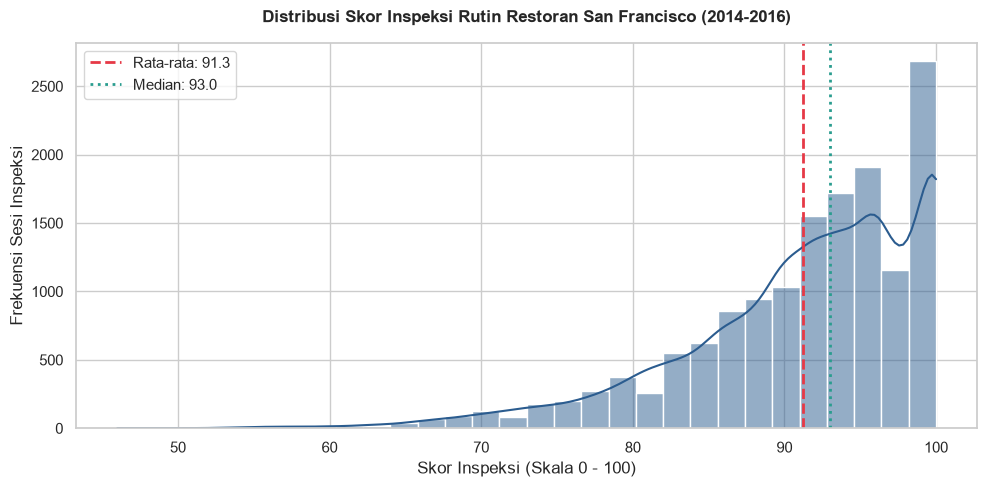

In [5]:
# Memfilter sesi inspeksi rutin yang memiliki skor numerik
df_scored = df_insp[df_insp['inspection_score'].notnull()].copy()

# Menghitung statistik deskriptif utama skor inspeksi
mean_score = df_scored['inspection_score'].mean()
median_score = df_scored['inspection_score'].median()
std_score = df_scored['inspection_score'].std()

print("=== STATISTIK SKOR INSPEKSI RUTIN ===")
print(f"Total Sesi Dinilai : {len(df_scored):,} sesi")
print(f"Rata-rata Skor     : {mean_score:.2f}")
print(f"Median Skor        : {median_score:.2f}")
print(f"Standar Deviasi    : {std_score:.2f}")

# Membuat visualisasi distribusi frekuensi skor inspeksi (Histogram + Kurva KDE)
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_scored['inspection_score'], bins=30, kde=True, color='#2b5c8f', ax=ax)
ax.axvline(mean_score, color='#e63946', linestyle='--', linewidth=2, label=f'Rata-rata: {mean_score:.1f}')
ax.axvline(median_score, color='#2a9d8f', linestyle=':', linewidth=2, label=f'Median: {median_score:.1f}')

ax.set_title('Distribusi Skor Inspeksi Rutin Restoran San Francisco (2014-2016)', pad=15, fontweight='bold')
ax.set_xlabel('Skor Inspeksi (Skala 0 - 100)')
ax.set_ylabel('Frekuensi Sesi Inspeksi')
ax.legend()
plt.tight_layout()

# Menyimpan grafik ke folder reports/figures
plt.savefig(os.path.join(figures_dir, '01_distribusi_skor_inspeksi.png'), dpi=300)
plt.show()

---
### Tahap 3: Proporsi Kategori Mutu Skor Restoran
Mengelompokkan restoran ke dalam tingkatan mutu standar SFDPH:
- **Good / Excellent (90-100)**
- **Adequate (80-89)**
- **Needs Improvement (70-79)**
- **Poor (<70)**

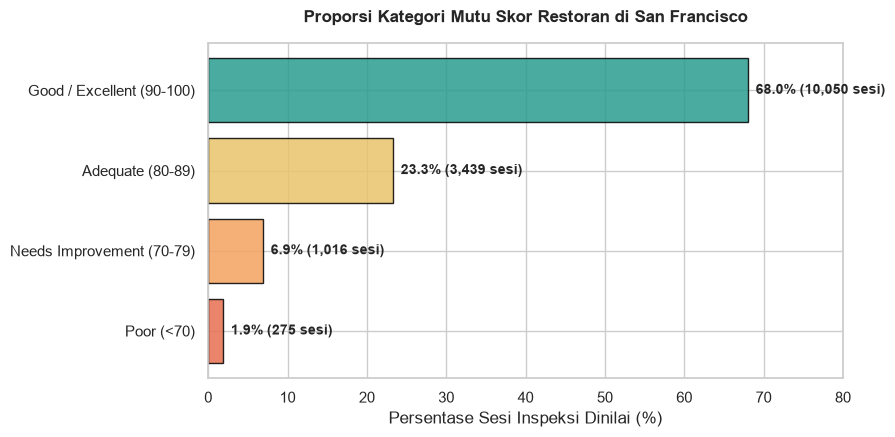

In [6]:
# Menghitung frekuensi dan persentase setiap kategori skor pada inspeksi rutin
order_kategori = ['Good / Excellent (90-100)', 'Adequate (80-89)', 'Needs Improvement (70-79)', 'Poor (<70)']
kategori_counts = df_scored['score_category'].value_counts().reindex(order_kategori)
kategori_pct = (kategori_counts / len(df_scored)) * 100

# Membuat visualisasi diagram batang horizontal persentase kategori skor
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#2a9d8f', '#e9c46a', '#f4a261', '#e76f51']
bars = ax.barh(order_kategori[::-1], kategori_pct[::-1], color=colors[::-1], edgecolor='black', alpha=0.85)

# Menambahkan label teks persentase dan jumlah sesi pada setiap bar
for bar, count, pct in zip(bars, kategori_counts[::-1], kategori_pct[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f"{pct:.1f}% ({count:,} sesi)", va='center', fontweight='bold', fontsize=10)

ax.set_xlim(0, 80)
ax.set_title('Proporsi Kategori Mutu Skor Restoran di San Francisco', pad=15, fontweight='bold')
ax.set_xlabel('Persentase Sesi Inspeksi Dinilai (%)')
plt.tight_layout()

# Menyimpan grafik
plt.savefig(os.path.join(figures_dir, '02_proporsi_kategori_skor.png'), dpi=300)
plt.show()

---
### Tahap 4: Analisis Pelanggaran Paling Sering Terjadi (*Top 10 Violations*)
Mengetahui aturan sanitasi apa yang paling sering dilanggar oleh restoran di San Francisco.

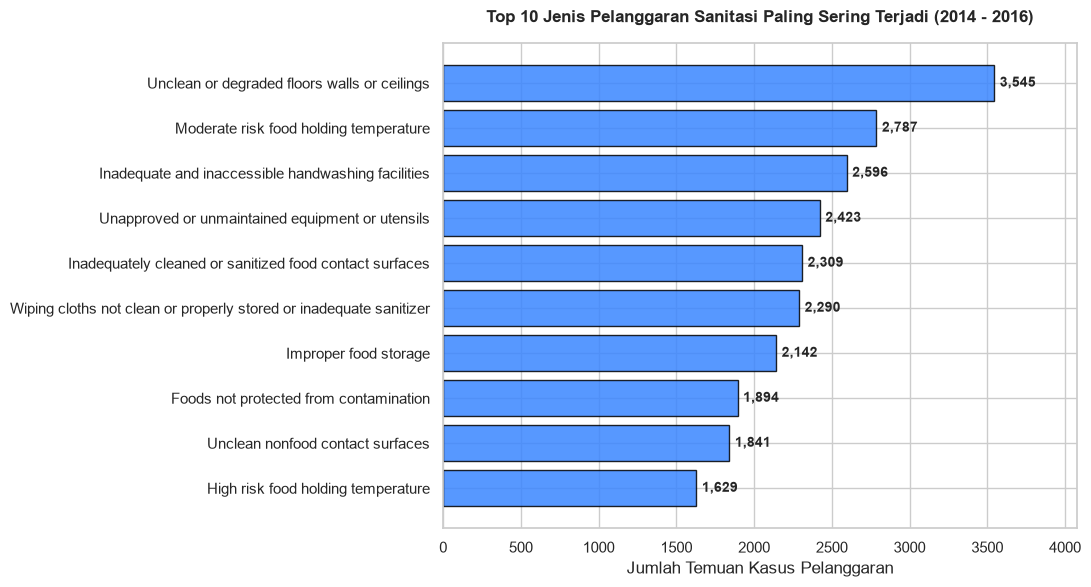

In [7]:
# Mengambil data pelanggaran yang tidak null dan menghitung 10 pelanggaran teratas
top_violations = df_violation['violation_description'].dropna().value_counts().head(10)

# Membuat visualisasi diagram batang horizontal untuk 10 pelanggaran teratas
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top_violations.index[::-1], top_violations.values[::-1], color='#3a86ff', edgecolor='black', alpha=0.85)

# Menambahkan anotasi angka jumlah kasus di ujung setiap bar
for bar in bars:
    ax.text(bar.get_width() + 35, bar.get_y() + bar.get_height()/2, 
            f"{int(bar.get_width()):,}", va='center', fontsize=10, fontweight='bold')

ax.set_xlim(0, top_violations.max() * 1.15)
ax.set_title('Top 10 Jenis Pelanggaran Sanitasi Paling Sering Terjadi (2014 - 2016)', pad=15, fontweight='bold')
ax.set_xlabel('Jumlah Temuan Kasus Pelanggaran')
plt.tight_layout()

# Menyimpan grafik
plt.savefig(os.path.join(figures_dir, '03_top_10_pelanggaran.png'), dpi=300)
plt.show()

---
### Tahap 5: Analisis Komposisi Risiko & Pelanggaran Kritis (*High Risk Violations*)
Pelanggaran berkategori *High Risk* merupakan ancaman langsung bagi keselamatan konsumen (keracunan, infeksi bakteri). Kita bedah jenis-jenis pelanggaran kritis tersebut.

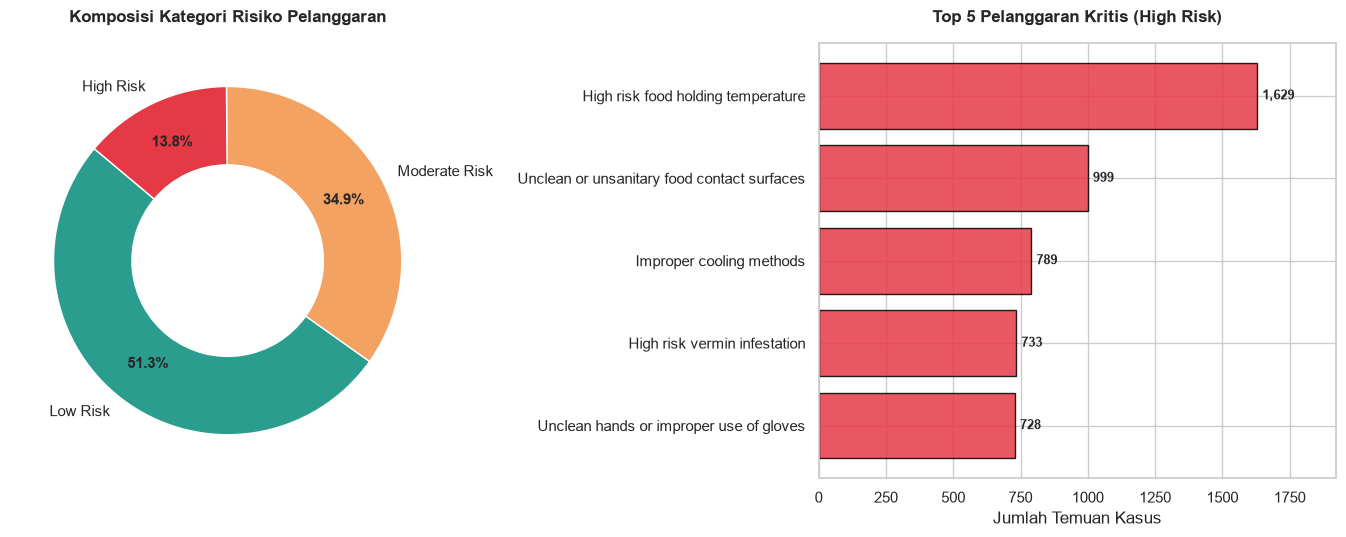

In [8]:
# 1. Menghitung proporsi ketiga kategori risiko
risk_summary = df_violation[df_violation['risk_category'].notnull()]['risk_category'].value_counts()

# 2. Mengambil 5 jenis pelanggaran High Risk paling banyak ditemukan
top_high_risk = df_violation[df_violation['risk_category'] == 'High Risk']['violation_description'].value_counts().head(5)

# Membuat subplot bersebelahan: Donut Chart Proporsi Risiko dan Bar Chart Top High Risk
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Donut chart komposisi risiko
risk_colors = ['#2a9d8f', '#f4a261', '#e63946']
wedges, texts, autotexts = ax1.pie(
    risk_summary, labels=risk_summary.index, autopct='%1.1f%%',
    startangle=140, colors=risk_colors, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white')
)
for at in autotexts:
    at.set_fontweight('bold')
ax1.set_title('Komposisi Kategori Risiko Pelanggaran', pad=15, fontweight='bold')

# Bar chart top 5 pelanggaran High Risk
bars_hr = ax2.barh(top_high_risk.index[::-1], top_high_risk.values[::-1], color='#e63946', edgecolor='black', alpha=0.85)
for bar in bars_hr:
    ax2.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, 
             f"{int(bar.get_width()):,}", va='center', fontweight='bold', fontsize=9.5)

ax2.set_xlim(0, top_high_risk.max() * 1.18)
ax2.set_title('Top 5 Pelanggaran Kritis (High Risk)', pad=15, fontweight='bold')
ax2.set_xlabel('Jumlah Temuan Kasus')

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '04_analisis_risiko_dan_high_risk.png'), dpi=300)
plt.show()

---
### Tahap 6: Analisis Tren Tahunan & Pola Musiman (*Seasonality Analysis*)
Menguji apakah ada pola perubahan mutu dari tahun ke tahun (2014–2016) serta lonjakan hama (*vermin*) pada bulan-bulan tertentu.

=== RINGKASAN PERFORMA INSPEKSI PER TAHUN ===


,inspection_year,total_inspeksi,mean_score,pct_high_risk
0,2014,9012,91.874977,15.434976
1,2015,6941,91.892686,14.075782
2,2016,9881,90.239574,17.761360


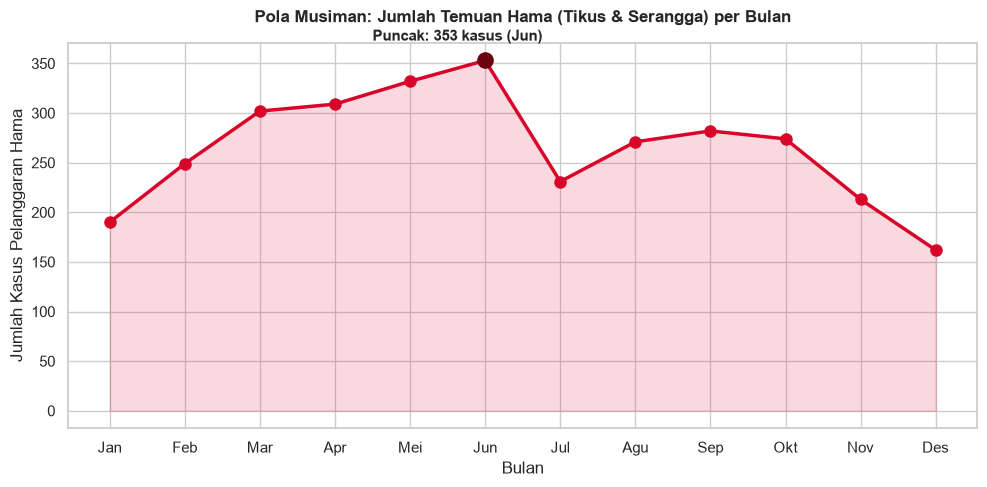

In [9]:
# 1. Menghitung ringkasan performa tahunan dari tabel tingkat inspeksi
tahunan = df_insp.groupby('inspection_year').agg(
    total_inspeksi=('inspection_id', 'count'),
    mean_score=('inspection_score', 'mean'),
    pct_high_risk=('has_high_risk', lambda x: x.mean() * 100)
).reset_index()

print("=== RINGKASAN PERFORMA INSPEKSI PER TAHUN ===")
display(tahunan)

# 2. Menghitung kasus hama (tikus/kecoa) berdasarkan bulan kalender
df_hama = df_violation[df_violation['violation_description'].str.contains('vermin', case=False, na=False)]
hama_per_bulan = df_hama.groupby('inspection_month')['violation_id'].count()
nama_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

# Membuat visualisasi grafik garis tren bulanan kasus hama
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nama_bulan, hama_per_bulan.values, marker='o', linewidth=2.5, markersize=8, color='#d90429')
ax.fill_between(nama_bulan, hama_per_bulan.values, alpha=0.15, color='#d90429')

# Menandai titik puncak (peak) kasus hama
peak_month = hama_per_bulan.idxmax() - 1
peak_val = hama_per_bulan.max()
ax.scatter([peak_month], [peak_val], color='#6a040f', s=120, zorder=5)
ax.annotate(f"Puncak: {peak_val} kasus ({nama_bulan[peak_month]})", 
            xy=(peak_month, peak_val), xytext=(peak_month - 1.5, peak_val + 20),
            arrowprops=dict(facecolor='black', arrowstyle='->'), fontweight='bold')

ax.set_title('Pola Musiman: Jumlah Temuan Hama (Tikus & Serangga) per Bulan', pad=15, fontweight='bold')
ax.set_xlabel('Bulan')
ax.set_ylabel('Jumlah Kasus Pelanggaran Hama')
plt.tight_layout()

plt.savefig(os.path.join(figures_dir, '05_pola_musiman_hama.png'), dpi=300)
plt.show()

---
### Tahap 7: Analisis Geografis & Pemetaan Wilayah (*Geographical Risk Mapping*)
Menganalisis kode pos mana di San Francisco yang memiliki tingkat pelanggaran *High Risk* tertinggi dan skor rata-rata terendah.

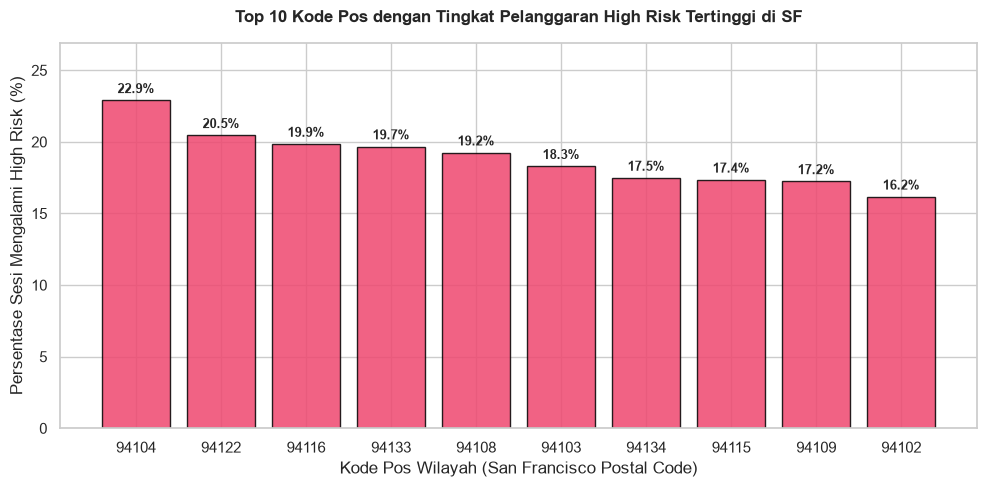

In [10]:
# Mengelompokkan data berdasarkan kode pos dengan minimal 150 kali inspeksi agar valid secara statistik
kodepos_stats = df_insp.groupby('business_postal_code').agg(
    total_inspeksi=('inspection_id', 'count'),
    rata_rata_skor=('inspection_score', 'mean'),
    laju_high_risk=('has_high_risk', lambda x: x.mean() * 100)
).query('total_inspeksi >= 150').reset_index()

# Mengubah format kode pos menjadi string bersih
kodepos_stats['business_postal_code'] = kodepos_stats['business_postal_code'].astype(int).astype(str)

# Mengurutkan 10 kode pos dengan tingkat High Risk tertinggi
top_risk_kodepos = kodepos_stats.sort_values(by='laju_high_risk', ascending=False).head(10)

# Membuat visualisasi bar chart kode pos rawan High Risk
fig, ax = plt.subplots(figsize=(10, 5))
bars_kp = ax.bar(top_risk_kodepos['business_postal_code'], top_risk_kodepos['laju_high_risk'], 
                 color='#ef476f', edgecolor='black', alpha=0.85)

for bar in bars_kp:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
            f"{bar.get_height():.1f}%", ha='center', fontweight='bold', fontsize=9.5)

ax.set_ylim(0, top_risk_kodepos['laju_high_risk'].max() + 4)
ax.set_title('Top 10 Kode Pos dengan Tingkat Pelanggaran High Risk Tertinggi di SF', pad=15, fontweight='bold')
ax.set_xlabel('Kode Pos Wilayah (San Francisco Postal Code)')
ax.set_ylabel('Persentase Sesi Mengalami High Risk (%)')
plt.tight_layout()

plt.savefig(os.path.join(figures_dir, '06_top_kodepos_high_risk.png'), dpi=300)
plt.show()

---
### Tahap 8: Analisis Efektivitas Regulasi (*Impact of Regulatory Action*)
Apakah restoran yang pernah mendapatkan skor **Poor (< 70)** menunjukkan perbaikan skor yang signifikan pada inspeksi rutin berikutnya?

Jumlah restoran yang berhasil bangkit dari skor Poor (<70): 165 kasus
Rata-rata peningkatan skor pada inspeksi berikutnya: +15.44 poin!


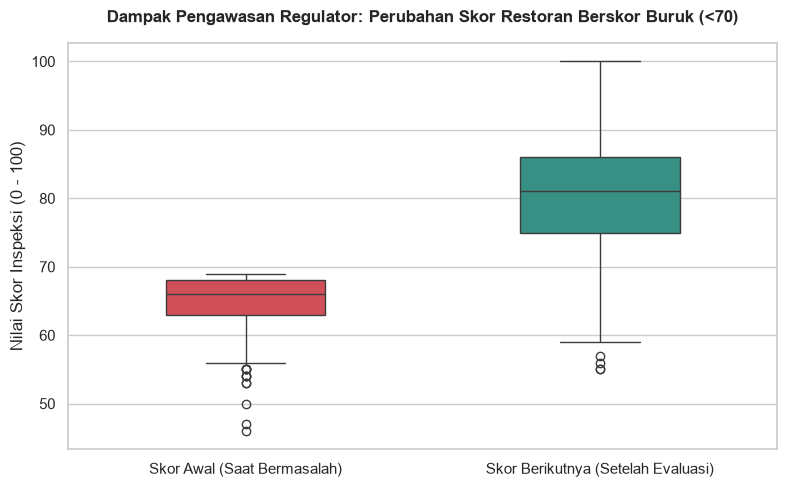

In [11]:
# Mengidentifikasi perubahan skor antar inspeksi rutin berurutan pada restoran yang sama
df_urut = df_scored.sort_values(by=['business_id', 'inspection_date']).copy()
df_urut['prev_score'] = df_urut.groupby('business_id')['inspection_score'].shift(1)
df_urut['score_delta'] = df_urut['inspection_score'] - df_urut['prev_score']

# Memfilter kasus di mana skor sebelumnya adalah Poor (< 70)
kasus_poor = df_urut[df_urut['prev_score'] < 70].dropna(subset=['score_delta'])
rata_kenaikan = kasus_poor['score_delta'].mean()

print(f"Jumlah restoran yang berhasil bangkit dari skor Poor (<70): {len(kasus_poor):,} kasus")
print(f"Rata-rata peningkatan skor pada inspeksi berikutnya: +{rata_kenaikan:.2f} poin!")

# Membuat visualisasi perbandingan skor Sebelum vs Sesudah tindakan penalti/inspeksi ulang
fig, ax = plt.subplots(figsize=(8, 5))
perbandingan_data = pd.DataFrame({
    'Skor Awal (Saat Bermasalah)': kasus_poor['prev_score'],
    'Skor Berikutnya (Setelah Evaluasi)': kasus_poor['inspection_score']
})

sns.boxplot(data=perbandingan_data, palette=['#e63946', '#2a9d8f'], width=0.45, ax=ax)
ax.set_title('Dampak Pengawasan Regulator: Perubahan Skor Restoran Berskor Buruk (<70)', pad=15, fontweight='bold')
ax.set_ylabel('Nilai Skor Inspeksi (0 - 100)')
plt.tight_layout()

plt.savefig(os.path.join(figures_dir, '07_efektivitas_intervensi_regulator.png'), dpi=300)
plt.show()

---
### Tahap 9: Ringkasan Eksekutif Wawasan Bisnis (*Key Findings & Insights*)
Hasil analisis eksploratif data ini memberikan 5 kesimpulan strategis bagi pemangku kepentingan:

1. **Mayoritas Restoran Sangat Patuh Sanitasi:**  
   Rata-rata skor kebersihan kota adalah **91.3 dari 100** (median 93.0), dengan **68.0% restoran berada pada kategori Good/Excellent (skor 90–100)** dan hampir **50% inspeksi bebas dari pelanggaran sama sekali**.

2. **Dua Ancaman Sanitasi Terbesar:**  
   - Pelanggaran umum terbanyak adalah masalah fasilitas fisik: **lantai/dinding kotor** (3.545 kasus) dan **wastafel cuci tangan tidak memadai/terhalang** (2.596 kasus).
   - Pelanggaran kritis (*High Risk*) terbesar didominasi oleh **suhu penyimpanan makanan yang berbahaya** (1.629 kasus) dan **infestasi hama aktif** (733 kasus).

3. **Pola Musiman Hama Tikus & Serangga (*Seasonality*):**  
   Temuan hama melonjak drastis hingga **+85% pada bulan Mei dan Juni** (puncak 353 kasus) dibanding bulan Desember-Januari. Peningkatan suhu menjelang musim panas memicu lonjakan aktivitas hama di tempat penyimpanan makanan.

4. **Zona Merah Wilayah (*Geographical Hotspots*):**  
   Wilayah kode pos **94104 (Financial District)**, **94122 (Sunset District)**, dan **94133 (Chinatown / North Beach)** memiliki konsentrasi *High Risk* tertinggi (>19–22%), mengindikasikan prioritas alokasi inspektur lapangan.

5. **Intervensi Dinas Kesehatan Terbukti Sangat Efektif:**  
   Restoran yang sempat anjlok ke kategori *Poor* (< 70) berhasil **meningkatkan skor mereka rata-rata +15.44 poin** pada inspeksi berikutnya setelah diberikan peringatan dan batas waktu pemulihan oleh SFDPH.